# Problem 13: Matrix Compression & Low-Rank SVD
**Algorithms & Data Structures Examination, Group 3**

From dense storage → Gram power iteration → matrix-free alternating power iteration → Hotelling deflation → truncated rank-k factored SVD.

| Stage | Name | Idea |
|---|---|---|
| V1 | Dense storage | `mn` floats (plus naive subsampling baseline) |
| V2 | Gram power iteration | form `G = AᵀA`, power-iterate on `G` |
| V3 | Matrix-free alternating power | alternate `Av`, `Aᵀu`; never form `AᵀA` |
| V4 | Hotelling deflation | `A ← A − σuvᵀ`, repeat k times |
| V5 | Truncated factored SVD | store `(U_k, σ_k, V_kᵀ)`: `k(m+n+1)` floats |

**Constraint from the sheet:** V2–V5 solvers use only matrix-vector products and vector norms (no `np.linalg.svd` inside them). `np.linalg.svd` is used *only* as a reference in tests/experiments.

In [26]:
import time, tracemalloc
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Part A: the hand-worked 3×2 example (numerical check)
`A = [[3,0],[4,5],[0,0]]`. We verify every number of the handwritten solution (Q1–Q3).

In [25]:
import numpy as np
A_small = np.array([[3., 0.], [4., 5.], [0., 0.]])

# Q1: Gram matrix, eigen-decomposition, singular vectors
G = A_small.T @ A_small
print("G = AᵀA =\n", G)
lam, W = np.linalg.eigh(G)               # reference only (2x2)
lam, W = lam[::-1], W[:, ::-1]
print("eigenvalues of G:", lam, "  -> sigma =", np.sqrt(lam))
print("exact: sigma1 = sqrt(45) =", np.sqrt(45), ", sigma2 = sqrt(5) =", np.sqrt(5))
v1, v2 = np.array([1, 1]) / np.sqrt(2), np.array([1, -1]) / np.sqrt(2)
s1, s2 = np.sqrt(45), np.sqrt(5)
u1, u2 = A_small @ v1 / s1, A_small @ v2 / s2
print("u1 =", u1, " = (1,3,0)/sqrt(10) =", np.array([1, 3, 0]) / np.sqrt(10))
print("u2 =", u2, " = (3,-1,0)/sqrt(10) =", np.array([3, -1, 0]) / np.sqrt(10))

# Q2: rank-1 approximation, Hotelling deflation, Frobenius error
A1 = s1 * np.outer(u1, v1)
print("\nA1 = sigma1 u1 v1ᵀ =\n", A1)
A_defl = A_small - A1
print("A - A1 =\n", A_defl)
print("equals sigma2 u2 v2ᵀ ?", np.allclose(A_defl, s2 * np.outer(u2, v2)))
print("||A - A1||_F =", np.linalg.norm(A_defl), " sigma2 =", s2)

# Q3: one iteration of Stage 3 from v0 = (1, 0)
v0 = np.array([1., 0.])
u_t = A_small @ v0;  nu = np.linalg.norm(u_t);  u_1 = u_t / nu
v_t = A_small.T @ u_1;  sig_1 = np.linalg.norm(v_t);  v_1 = v_t / sig_1
print("\nQ3: u~ =", u_t, " ||u~|| =", nu, " u(1) =", u_1)
print("    v~ =", v_t, " sigma1(1) = sqrt(41) =", sig_1, " v(1) =", v_1)
print("    exact sigma1 = %.4f, exact v1 = %s" % (s1, v1))

G = AᵀA =
 [[25. 20.]
 [20. 25.]]
eigenvalues of G: [45.  5.]   -> sigma = [6.70820393 2.23606798]
exact: sigma1 = sqrt(45) = 6.708203932499369 , sigma2 = sqrt(5) = 2.23606797749979
u1 = [0.31622777 0.9486833  0.        ]  = (1,3,0)/sqrt(10) = [0.31622777 0.9486833  0.        ]
u2 = [ 0.9486833  -0.31622777  0.        ]  = (3,-1,0)/sqrt(10) = [ 0.9486833  -0.31622777  0.        ]

A1 = sigma1 u1 v1ᵀ =
 [[1.5 1.5]
 [4.5 4.5]
 [0.  0. ]]
A - A1 =
 [[ 1.5 -1.5]
 [-0.5  0.5]
 [ 0.   0. ]]
equals sigma2 u2 v2ᵀ ? True
||A - A1||_F = 2.23606797749979  sigma2 = 2.23606797749979

Q3: u~ = [3. 4. 0.]  ||u~|| = 5.0  u(1) = [0.6 0.8 0. ]
    v~ = [5. 4.]  sigma1(1) = sqrt(41) = 6.4031242374328485  v(1) = [0.78086881 0.62469505]
    exact sigma1 = 6.7082, exact v1 = [0.70710678 0.70710678]


## V1: Dense storage and naive subsampling (baseline)
Dense storage keeps all `mn` floats (exact, `Ax` costs `Θ(mn)`). *Naive subsampling* (drop every 2nd row/column) saves 4× memory but ignores global structure, so sharp edges are destroyed.

In [3]:
class DenseMatrix:
    # V1: the whole matrix, row-major, mn floats.
    def __init__(self, A): self.A = np.array(A, dtype=float)
    def storage(self): return self.A.size
    def matvec(self, x): return self.A @ x            # Θ(mn)
    def reconstruct(self): return self.A

def naive_subsample(A, step=2):
    # Keep every `step`-th row/column, then blow back up by repetition.
    S = A[::step, ::step]
    big = np.repeat(np.repeat(S, step, axis=0), step, axis=1)
    return S, big[:A.shape[0], :A.shape[1]]

## V2: Explicit Gram matrix `G = AᵀA` + single-vector power iteration
`(AᵀA) vᵢ = σᵢ² vᵢ`, so `v₁` is the dominant eigenvector of `G`. Two bottlenecks: forming `G` costs `Θ(mn²)`, and `κ(AᵀA) = κ(A)²` destroys small singular values.
For the top-k we deflate `G` itself (`G ← G − λvvᵀ`, which is `Θ(n²)`) and recover `u = Av/σ`.

In [4]:
def power_iteration_sym(G, tol=1e-12, max_iter=50_000, rng=None):
    # Dominant eigenpair of a symmetric PSD matrix via v <- Gv/||Gv||.
    rng = rng or np.random.default_rng(0)
    v = rng.standard_normal(G.shape[0]); v /= np.linalg.norm(v)
    lam = 0.0
    for t in range(1, max_iter + 1):
        w = G @ v
        lam = np.linalg.norm(w)
        if lam == 0.0:
            return v, 0.0, t
        v_new = w / lam
        if np.linalg.norm(v_new - v) <= tol:
            return v_new, lam, t
        v = v_new
    return v, lam, max_iter

def svd_v2_gram(A, k, tol=1e-12, max_iter=50_000, seed=0):
    rng = np.random.default_rng(seed)
    m, n = A.shape
    G = A.T @ A                                   # Θ(mn²) time, n² memory  <-- bottleneck
    U = np.zeros((m, k)); s = np.zeros(k); Vt = np.zeros((k, n)); iters = []
    for j in range(k):
        v, lam, it = power_iteration_sym(G, tol, max_iter, rng)
        sigma = np.sqrt(max(lam, 0.0))            # lam = sigma² (squared!)
        U[:, j] = (A @ v) / sigma if sigma > 0 else 0.0
        s[j], Vt[j] = sigma, v
        G = G - lam * np.outer(v, v)              # deflate the Gram matrix, Θ(n²)
        iters.append(it)
    return U, s, Vt, iters

## V3: Matrix-free two-sided alternating power iteration
Never form `AᵀA`. Each iteration: `ũ = Av → u = ũ/‖ũ‖ → ṽ = Aᵀu → σ = ‖ṽ‖ → v = ṽ/σ`. Two mat-vecs, `Θ(mn)` time, `Θ(m+n)` extra space. The operator is passed as two callables so V4 can reuse it.

In [5]:
def alt_power_triplet(matvec, rmatvec, n, tol=1e-12, max_iter=50_000, rng=None):
    # Dominant singular triplet (sigma, u, v) using only A·v and Aᵀ·u.
    rng = rng or np.random.default_rng(0)
    v = rng.standard_normal(n); v /= np.linalg.norm(v)
    sigma = 0.0
    for t in range(1, max_iter + 1):
        u_t = matvec(v);   nu = np.linalg.norm(u_t)       # ũ = A v
        if nu == 0.0:
            return 0.0, u_t, v, t
        u = u_t / nu
        v_t = rmatvec(u);  sigma = np.linalg.norm(v_t)    # ṽ = Aᵀ u,  σ = ||ṽ||
        v_new = v_t / sigma
        if np.linalg.norm(v_new - v) <= tol:
            v = v_new
            break
        v = v_new
    u_t = matvec(v); sigma = np.linalg.norm(u_t); u = u_t / sigma   # consistent final triplet
    return sigma, u, v, t

def svd_v3_top1(A, **kw):
    return alt_power_triplet(lambda x: A @ x, lambda y: A.T @ y, A.shape[1], **kw)

## V4: Hotelling rank-1 deflation
After finding `(σ₁,u₁,v₁)`, set `A⁽¹⁾ = A − σ₁u₁v₁ᵀ` and run V3 again; repeat k times. `Θ(k·T·mn)` time.
* `implicit=False`: explicit deflated copy (`+mn` memory, exactly as in the sheet).
* `implicit=True`: never modify/copy `A`; apply `(A − Σσⱼuⱼvⱼᵀ)x = Ax − Σσⱼuⱼ(vⱼᵀx)` on the fly (`+k(m+n)` memory, truly matrix-free).

In [6]:
def svd_v4_deflation(A, k, implicit=False, tol=1e-12, max_iter=50_000, seed=0):
    rng = np.random.default_rng(seed)
    m, n = A.shape
    U = np.zeros((m, k)); s = np.zeros(k); Vt = np.zeros((k, n)); iters = []
    if not implicit:
        R = A.copy()                                   # A^(0); Θ(mn) extra memory
        for j in range(k):
            sg, u, v, it = alt_power_triplet(lambda x: R @ x, lambda y: R.T @ y, n, tol, max_iter, rng)
            R -= sg * np.outer(u, v)                   # A^(j+1) = A^(j) − σ u vᵀ
            U[:, j], s[j], Vt[j] = u, sg, v; iters.append(it)
    else:
        for j in range(k):
            Uj, sj, Vj = U[:, :j], s[:j], Vt[:j]
            mv  = lambda x: A @ x   - Uj @ (sj * (Vj @ x))
            rmv = lambda y: A.T @ y - Vj.T @ (sj * (Uj.T @ y))
            sg, u, v, it = alt_power_triplet(mv, rmv, n, tol, max_iter, rng)
            U[:, j], s[j], Vt[j] = u, sg, v; iters.append(it)
    return U, s, Vt, iters

## V5: Truncated rank-k factored data structure `(U_k, σ_k, V_kᵀ)`
Memory `mn → k(m+n+1)`; `Ax` costs `Θ(k(m+n))` via `U_k(σ_k ⊙ (V_kᵀx))`; by Eckart–Young `‖A−A_k‖_F = √(Σ_{i>k}σᵢ²)`.

In [7]:
class TruncatedSVD:
    # V5: three compact arrays instead of the dense matrix.
    def __init__(self, U, s, Vt): self.U, self.s, self.Vt = U, s, Vt
    @classmethod
    def fit(cls, A, k, **kw):
        U, s, Vt, _ = svd_v4_deflation(A, k, **kw)
        return cls(U, s, Vt)
    @property
    def shape(self): return (self.U.shape[0], self.Vt.shape[1])
    def storage(self):
        m, n = self.shape; return self.s.size * (m + n + 1)       # k(m+n+1)
    def matvec(self, x):  return self.U @ (self.s * (self.Vt @ x))   # Θ(k(m+n))
    def rmatvec(self, y): return self.Vt.T @ (self.s * (self.U.T @ y))
    def reconstruct(self): return (self.U * self.s) @ self.Vt
    def fro_error(self, A): return np.linalg.norm(A - self.reconstruct())
    def energy(self, A):    return float(np.sum(self.s**2) / np.sum(A**2))

## Unit tests: all versions must agree with each other and with the theory

In [24]:
import time
import numpy as np

A_small = np.array([[3., 0.], [4., 5.], [0., 0.]])

def make_test_matrix(m, n, decay=0.8, scale=10.0, seed=0):
    # A = Q1 diag(s) Q2ᵀ with known geometric spectrum s_i = scale*decay**i.
    rng = np.random.default_rng(seed)
    Q1, _ = np.linalg.qr(rng.standard_normal((m, n)))
    Q2, _ = np.linalg.qr(rng.standard_normal((n, n)))
    s = scale * decay ** np.arange(n)
    return (Q1 * s) @ Q2.T, s

def test_part_a_all_versions():
    exact = np.array([np.sqrt(45), np.sqrt(5)])
    for name, (_, s, _, _) in {
        "V2": svd_v2_gram(A_small, 2),
        "V4 explicit": svd_v4_deflation(A_small, 2),
        "V4 implicit": svd_v4_deflation(A_small, 2, implicit=True)}.items():
        assert np.allclose(s, exact, atol=1e-9), (name, s)
    sg, u, v, _ = svd_v3_top1(A_small)
    assert abs(sg - np.sqrt(45)) < 1e-9 and np.allclose(abs(v), [1/np.sqrt(2)]*2, atol=1e-8)

def test_singular_values_match_reference():
    A, _ = make_test_matrix(300, 60)
    ref = np.linalg.svd(A, compute_uv=False)[:6]
    for name, out in {"V2": svd_v2_gram(A, 6), "V4 explicit": svd_v4_deflation(A, 6),
                      "V4 implicit": svd_v4_deflation(A, 6, implicit=True)}.items():
        assert np.max(np.abs(out[1] - ref)) < 1e-6, name

def test_orthonormality_and_residuals():
    A, _ = make_test_matrix(300, 60)
    U, s, Vt, _ = svd_v4_deflation(A, 6)
    assert np.allclose(U.T @ U, np.eye(6), atol=1e-6) and np.allclose(Vt @ Vt.T, np.eye(6), atol=1e-6)
    assert np.allclose(A @ Vt.T, U * s, atol=1e-6)               # A v_i = σ_i u_i

def test_v5_factored_ops_and_eckart_young():
    A, s_true = make_test_matrix(300, 60)
    k = 8
    F = TruncatedSVD.fit(A, k)
    x = np.random.default_rng(1).standard_normal(60)
    assert np.allclose(F.matvec(x), F.reconstruct() @ x)         # factored Ax == dense A_k x
    assert F.storage() == k * (300 + 60 + 1)
    tail = np.sqrt(np.sum(s_true[k:] ** 2))
    assert abs(F.fro_error(A) - tail) / tail < 1e-6              # Eckart–Young

def test_v1_subsampling_is_lossy():
    A, _ = make_test_matrix(64, 64, decay=0.9)
    _, big = naive_subsample(A)
    assert np.linalg.norm(A - big) > 0.1 * np.linalg.norm(A)

for t in [test_part_a_all_versions, test_singular_values_match_reference,
          test_orthonormality_and_residuals, test_v5_factored_ops_and_eckart_young,
          test_v1_subsampling_is_lossy]:
    t(); print("PASS ", t.__name__)

PASS  test_part_a_all_versions
PASS  test_singular_values_match_reference
PASS  test_orthonormality_and_residuals
PASS  test_v5_factored_ops_and_eckart_young
PASS  test_v1_subsampling_is_lossy


## Part B (numerical check of Q4)
Energy retained by `A₁`, and the storage/compression arithmetic for a 1000×1000 image.

In [10]:
print("Energy captured by A1 on the 3x2 example: %.1f %%" % (100 * 45 / (45 + 5)))
m, n, k = 1000, 1000, 25
dense, fact = m * n, k * (m + n + 1)
print(f"k=25: dense = {dense:,} floats, factored = {fact:,} floats, ratio = {dense/fact:.3f}")
k_cross = m * n / (m + n + 1)
print(f"break-even k = mn/(m+n+1) = {k_cross:.2f}  ->  k=499 uses {499*(m+n+1):,} floats (saves),"
      f" k=500 uses {500*(m+n+1):,} floats (MORE than {dense:,})")

Energy captured by A1 on the 3x2 example: 90.0 %
k=25: dense = 1,000,000 floats, factored = 50,025 floats, ratio = 19.990
break-even k = mn/(m+n+1) = 499.75  ->  k=499 uses 998,499 floats (saves), k=500 uses 1,000,500 floats (MORE than 1,000,000)


## Experiment 1: V2 (Gram) vs V3+V4 (matrix-free + deflation), 2000×400, top k=10
Verify singular values against `np.linalg.svd` (tolerance 1e-6) and compare wall-clock time.

In [16]:
import time
def timeit(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); out = f(); best = min(best, time.perf_counter() - t0)
    return best, out

A_e1, _ = make_test_matrix(2000, 400, decay=0.8, seed=1)
K = 10
ref = np.linalg.svd(A_e1, compute_uv=False)[:K]

t_v2,  (U2, s2_, V2t, it2) = timeit(lambda: svd_v2_gram(A_e1, K))
t_v4,  (U4, s4_, V4t, it4) = timeit(lambda: svd_v4_deflation(A_e1, K))
t_v4i, (U4i, s4i, V4it, it4i) = timeit(lambda: svd_v4_deflation(A_e1, K, implicit=True))

print(f"{'method':22s} {'time [s]':>9s} {'max |σ − σ_ref|':>17s} {'total iters':>12s}")
for name, t, s_, it in [("V2 Gram + power", t_v2, s2_, it2),
                        ("V3+V4 explicit", t_v4, s4_, it4),
                        ("V3+V4 implicit", t_v4i, s4i, it4i)]:
    err = np.max(np.abs(s_ - ref))
    print(f"{name:22s} {t:9.4f} {err:17.2e} {sum(it):12d}")
    assert err < 1e-6
print("\nTop-10 singular values (reference):", ref)

method                  time [s]   max |σ − σ_ref|  total iters
V2 Gram + power           0.0602          1.78e-15          616
V3+V4 explicit            0.4077          1.78e-15          616
V3+V4 implicit            0.4506          1.78e-15          616

Top-10 singular values (reference): [10.          8.          6.4         5.12        4.096       3.2768
  2.62144     2.097152    1.6777216   1.34217728]


**Reading the result honestly.** All three agree with `np.linalg.svd` to ~1e-14, but in *wall-clock time* V2 is faster here. This follows from the cost model: V2 pays `mn²` once to form `G`, then each iteration costs only `n²`; V3 pays `2mn` per iteration. With `m ≫ n` and many iterations (`k·T ≈ 600`), `mn² + kTn² ≪ 2kT·mn`. What V3/V4 buys is **(i) numerical accuracy** (see the conditioning demo below) and **(ii) memory**: V2 stores an `n×n` Gram matrix and the implicit V4 stores only `O(k(m+n))` extra, which matters when `n` is large or `A` is only available as an operator (sparse, streamed, or `Av` computed on the fly). The crossover in *time* appears when `n` is comparable to `m`, or when `A` is sparse so that `Av` is much cheaper than `mn`, while the crossover in *accuracy* appears as soon as `κ(A)² ~ 1/ε`.

### Scaling benchmark: time and peak memory vs. matrix size
`m = 4n`, `k = 10`, increasing `n`. Peak memory is the extra memory allocated by the solver (measured with `tracemalloc`).

n=  50  V2 Gram: 0.008s/0.1MiB  V3+V4 explicit: 0.015s/0.3MiB  V3+V4 implicit: 0.019s/0.0MiB
n= 100  V2 Gram: 0.010s/0.3MiB  V3+V4 explicit: 0.021s/1.0MiB  V3+V4 implicit: 0.027s/0.1MiB
n= 200  V2 Gram: 0.011s/1.0MiB  V3+V4 explicit: 0.056s/3.7MiB  V3+V4 implicit: 0.061s/0.1MiB
n= 400  V2 Gram: 0.048s/3.8MiB  V3+V4 explicit: 0.365s/14.8MiB  V3+V4 implicit: 0.308s/0.2MiB
n= 800  V2 Gram: 0.215s/15.0MiB  V3+V4 explicit: 2.000s/58.9MiB  V3+V4 implicit: 1.859s/0.5MiB


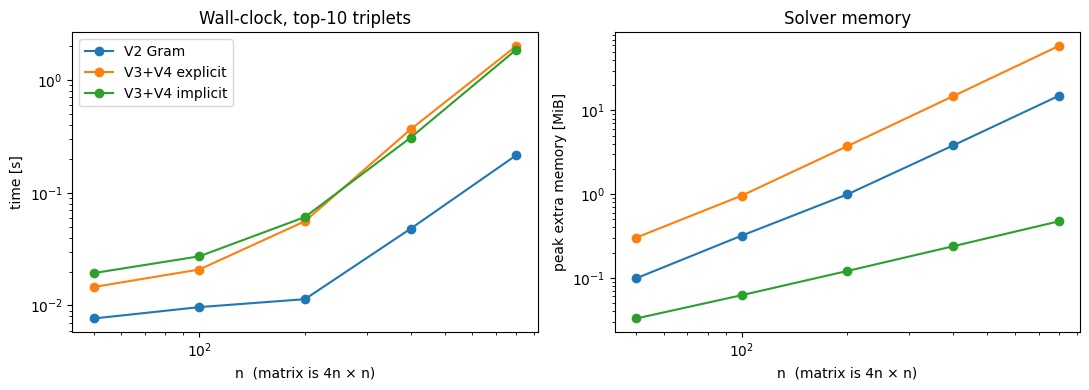

In [19]:
import time, tracemalloc
import numpy as np
import matplotlib.pyplot as plt

def peak_mem(f):
    tracemalloc.start(); f(); _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return peak / 2**20   # MiB

sizes = [50, 100, 200, 400, 800]
bench = {"V2 Gram": [], "V3+V4 explicit": [], "V3+V4 implicit": []}
mem   = {k_: [] for k_ in bench}
solvers = {"V2 Gram": lambda A: svd_v2_gram(A, K),
           "V3+V4 explicit": lambda A: svd_v4_deflation(A, K),
           "V3+V4 implicit": lambda A: svd_v4_deflation(A, K, implicit=True)}
for n_ in sizes:
    A_, _ = make_test_matrix(4 * n_, n_, decay=0.8, seed=2)
    for name, f in solvers.items():
        t, _ = timeit(lambda: f(A_), repeat=2)
        bench[name].append(t); mem[name].append(peak_mem(lambda: f(A_)))
    print(f"n={n_:4d}  " + "  ".join(f"{k_}: {bench[k_][-1]:.3f}s/{mem[k_][-1]:.1f}MiB" for k_ in bench))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in bench:
    ax[0].plot(sizes, bench[name], "o-", label=name); ax[1].plot(sizes, mem[name], "o-", label=name)
ax[0].set(xlabel="n  (matrix is 4n × n)", ylabel="time [s]", title="Wall-clock, top-10 triplets", xscale="log", yscale="log")
ax[1].set(xlabel="n  (matrix is 4n × n)", ylabel="peak extra memory [MiB]", title="Solver memory", xscale="log", yscale="log")
ax[0].legend(); plt.tight_layout(); plt.show()

### Why not just use V2? Numerical accuracy (the squared condition number)
`G = AᵀA` squares the singular values, so `σ = 10⁻⁹` becomes `λ = 10⁻¹⁸`, below double-precision resolution relative to `λ₁ = 1`. V3/V4 never square anything.

In [13]:
rng = np.random.default_rng(5)
Q1, _ = np.linalg.qr(rng.standard_normal((200, 30)))
Q2, _ = np.linalg.qr(rng.standard_normal((30, 30)))
s_true = np.zeros(30); s_true[:3] = [1.0, 1e-5, 1e-9]; s_true[3:] = 1e-12
A_ill = (Q1 * s_true) @ Q2.T

_, s_v2, _, _ = svd_v2_gram(A_ill, 3)
_, s_v4, _, _ = svd_v4_deflation(A_ill, 3, tol=1e-14)
fmt = lambda a: "[" + ", ".join(f"{x:.3e}" for x in a) + "]"
print("true  σ        :", fmt(s_true[:3]))
print("V2    σ        :", fmt(s_v2), "  relative errors:", fmt(np.abs(s_v2 - s_true[:3]) / s_true[:3]))
print("V3/V4 σ        :", fmt(s_v4), "  relative errors:", fmt(np.abs(s_v4 - s_true[:3]) / s_true[:3]))

true  σ        : [1.000e+00, 1.000e-05, 1.000e-09]
V2    σ        : [1.000e+00, 1.000e-05, 1.428e-08]   relative errors: [1.110e-16, 1.825e-08, 1.328e+01]
V3/V4 σ        : [1.000e+00, 1.000e-05, 1.000e-09]   relative errors: [1.110e-16, 1.501e-13, 2.646e-09]


## Experiment 2: image compression and the Eckart–Young energy curve
A 256×256 grayscale test image (smooth gradient, blobs, a ring, sharp-edged rectangle, diagonal stripes, text-like strokes, mild noise). Reconstruct `A_k` for `k ∈ {1,3,10,25,60}` with the V5 factored structure built by V3+V4.

V3+V4 extracted 60 triplets in 0.9s; 0 triplets hit the iteration cap
max |σ_i − σ_ref| over first 60: 5.684341886080802e-14


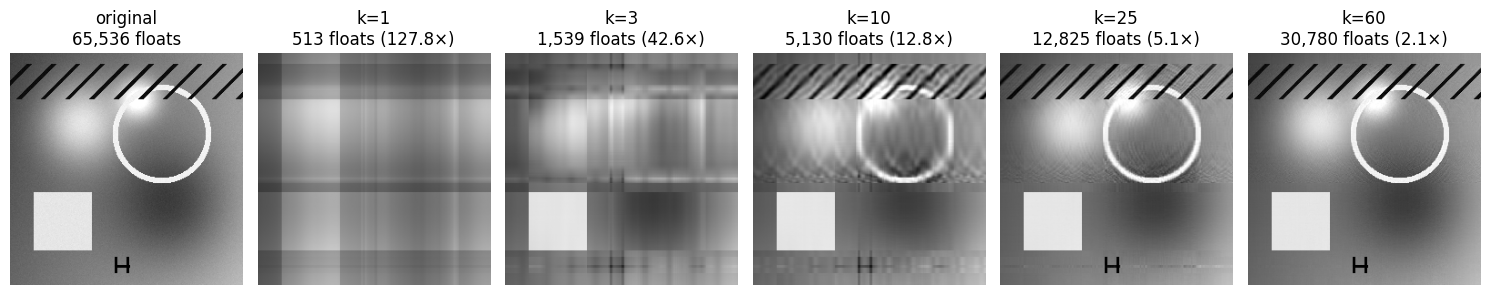

In [22]:
import time
import numpy as np
import matplotlib.pyplot as plt

def make_image(N=256, seed=0):
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[0:N, 0:N] / N
    img = 0.25 + 0.35 * x + 0.15 * y                                       # smooth gradient
    for cx, cy, r, a in [(0.3, 0.3, 0.12, 0.5), (0.7, 0.65, 0.18, -0.35), (0.55, 0.2, 0.06, 0.6)]:
        img += a * np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * r ** 2))  # blobs
    ring = np.abs(np.hypot(x - 0.65, y - 0.35) - 0.2) < 0.012;  img[ring] = 0.95   # thin ring
    img[(x > 0.1) & (x < 0.35) & (y > 0.6) & (y < 0.85)] = 0.9                       # sharp rectangle
    img[(np.sin(60 * (x + y)) > 0.8) & (y > 0.05) & (y < 0.2)] = 0.05                # diagonal stripes
    for (y0, x0, h, w) in [(0.88, 0.45, 0.07, 0.012), (0.88, 0.50, 0.07, 0.012), (0.915, 0.45, 0.012, 0.067)]:
        img[int(y0 * N):int((y0 + h) * N), int(x0 * N):int((x0 + w) * N)] = 0.0       # text-like strokes
    img += 0.01 * rng.standard_normal((N, N))
    return np.clip(img, 0, 1)

IMG = make_image()
KS = [1, 3, 10, 25, 60]
t0 = time.perf_counter()
U_i, s_i, Vt_i, it_i = svd_v4_deflation(IMG, 60, tol=1e-9, max_iter=5000)
print(f"V3+V4 extracted 60 triplets in {time.perf_counter()-t0:.1f}s; "
      f"{sum(i == 5000 for i in it_i)} triplets hit the iteration cap")
s_ref = np.linalg.svd(IMG, compute_uv=False)               # reference only
print("max |σ_i − σ_ref| over first 60:", np.max(np.abs(s_i - s_ref[:60])))

fig, axes = plt.subplots(1, len(KS) + 1, figsize=(15, 3.2))
axes[0].imshow(IMG, cmap="gray", vmin=0, vmax=1); axes[0].set_title("original\n65,536 floats"); axes[0].axis("off")
for ax, k_ in zip(axes[1:], KS):
    F = TruncatedSVD(U_i[:, :k_], s_i[:k_], Vt_i[:k_])
    ax.imshow(np.clip(F.reconstruct(), 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k={k_}\n{F.storage():,} floats ({IMG.size / F.storage():.1f}×)"); ax.axis("off")
plt.tight_layout(); plt.show()

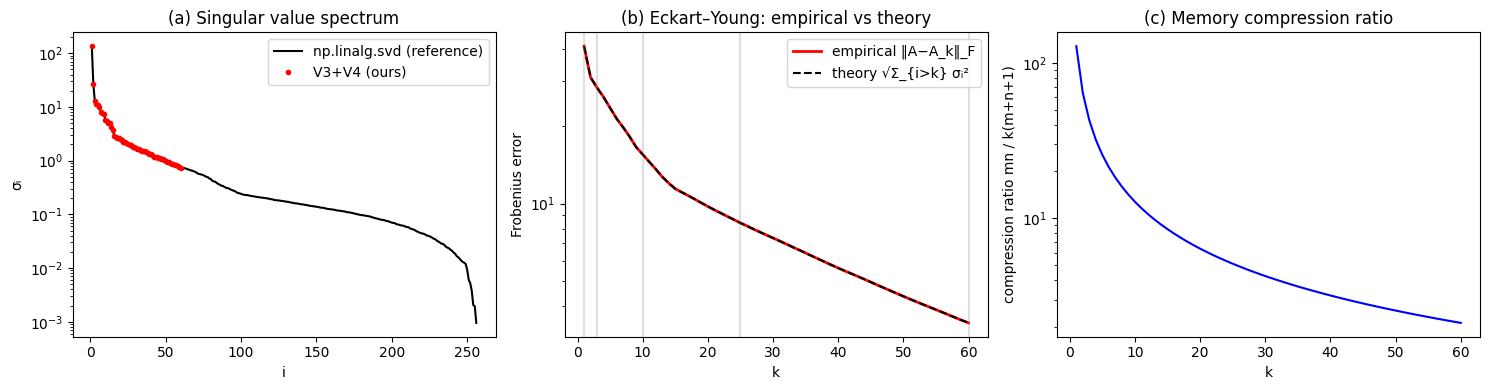

  k  empirical     theory  energy %   ratio
  1    41.0849    41.0849    91.572  127.75
  3    28.2961    28.2961    96.002   42.58
 10    15.5545    15.5545    98.792   12.78
 25     8.4080     8.4080    99.647    5.11
 60     3.4300     3.4300    99.941    2.13


In [23]:
tail_theory = np.sqrt(np.array([np.sum(s_ref[k_:] ** 2) for k_ in range(0, 61)]))
emp = np.array([0.0] + [np.linalg.norm(IMG - (U_i[:, :k_] * s_i[:k_]) @ Vt_i[:k_]) for k_ in range(1, 61)])
ratio = IMG.size / np.array([max(k_, 1) * (sum(IMG.shape) + 1) for k_ in range(61)])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(np.arange(1, len(s_ref) + 1), s_ref, "k-", lw=1.5, label="np.linalg.svd (reference)")
ax[0].semilogy(np.arange(1, 61), s_i, "r.", label="V3+V4 (ours)")
ax[0].set(xlabel="i", ylabel="σᵢ", title="(a) Singular value spectrum"); ax[0].legend()
ax[1].semilogy(range(1, 61), emp[1:], "r-", lw=2, label="empirical ‖A−A_k‖_F")
ax[1].semilogy(range(1, 61), tail_theory[1:], "k--", lw=1.5, label="theory √Σ_{i>k} σᵢ²")
for k_ in KS: ax[1].axvline(k_, color="gray", alpha=0.25)
ax[1].set(xlabel="k", ylabel="Frobenius error", title="(b) Eckart–Young: empirical vs theory"); ax[1].legend()
ax[2].plot(range(1, 61), ratio[1:], "b-"); ax[2].set(xlabel="k", ylabel="compression ratio mn / k(m+n+1)",
      title="(c) Memory compression ratio"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

print(f"{'k':>3s} {'empirical':>10s} {'theory':>10s} {'energy %':>9s} {'ratio':>7s}")
for k_ in KS:
    print(f"{k_:3d} {emp[k_]:10.4f} {tail_theory[k_]:10.4f} {100*np.sum(s_ref[:k_]**2)/np.sum(IMG**2):9.3f} {ratio[k_]:7.2f}")
assert np.allclose(emp[1:], tail_theory[1:], rtol=1e-3)

## Complexity summary (m ≥ n, `T` = iterations per triplet)
| | Construction time | Storage | `Ax` | `‖A−A_k‖_F` |
|---|---|---|---|---|
| V1 dense | `Θ(mn)` (copy) | `mn` | `Θ(mn)` | `0` (exact) |
| V2 Gram + power | `Θ(mn² + kTn²)` | `mn + n²` | `Θ(mn)` | `≥ √Σ_{i>k}σᵢ²`, loses small σ (κ²) |
| V3 matrix-free (1 triplet) | `Θ(T·mn)` | `mn + O(m+n)` | `Θ(mn)` | n/a (one triplet) |
| V4 deflation | `Θ(k·T·mn)` | `mn + mn` (explicit) or `mn + k(m+n)` (implicit) | `Θ(mn)` | `√Σ_{i>k}σᵢ²` |
| V5 truncated | `Θ(k·T·mn)` | `k(m+n+1)` | `Θ(k(m+n))` | `√Σ_{i>k}σᵢ²` (optimal) |